# Grok vs. Gemini as fact-checkers on X: agreement and corrective reach

Statistical analysis behind the paper *"True but invisible"* (UPF Barcelona School of Management, 2026).

**Questions**
1. How often does Grok's fact-check verdict agree with an independent model (Gemini)?
2. Which factors (topic, language, collection period) explain their disagreement?
3. How much of the original claim's audience does Grok's correction actually reach?

**Data:** `data/annotations.csv` - 2,493 real X interactions (claim -> user asks @grok -> Grok's reply),
with tweet IDs, view counts and the LLM-generated labels. Tweet text is not distributed
(see `data/README.md`); every number in this notebook can be reproduced from this file.

**Key results** (n = 2,353 after filtering)
- Grok and Gemini agree in **~82%** of cases (51% `same` + 31% `mostly_same`).
- Controlling for everything else, disagreement concentrates in **war** and **politics**; language and period effects are significant but small.
- The median Grok fact-check reaches **0.3%** of the audience of the tweet it corrects.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scikit_posthocs as sp
import statsmodels.formula.api as smf
from scipy.stats import (chisquare, chi2_contingency, kruskal,
                         mannwhitneyu, spearmanr)
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests

DATA = Path("../data/annotations.csv")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)
RNG = np.random.default_rng(42)

# Visual style: one blue ramp for ordered categories, recessive grid, no chartjunk
BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK, INK_2 = "#0b0b0b", "#52514e"
VERDICT_ORDER = ["disparity", "slight_diff", "mostly_same", "same"]  # low -> high agreement
VERDICT_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#184f95"]
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
})

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", facecolor="white")
    plt.show()

pd.set_option("display.max_columns", 50)

## 1. Load and prepare the data

Two filters, applied before any test:
1. Drop `comparison_verdict = unknown` - the judge model could not compare the two fact-checks, so it is not a degree of agreement.
2. Keep English and Spanish only - other languages have 1-20 observations each, which distorts the tests and causes perfect separation in the regression.

In [2]:
df = pd.read_csv(DATA, dtype={"grok_reply_id": str, "request_tweet_id": str, "claim_tweet_id": str})
n0 = len(df)
df = df[df["comparison_verdict"].isin(VERDICT_ORDER)].copy()
n1 = len(df)
df = df[df["lang"].isin(["en", "es"])].copy()
print(f"Initial rows: {n0}")
print(f"Removed (verdict unknown): {n0 - n1}")
print(f"Removed (language not en/es): {n1 - len(df)}")
print(f"Analysis sample: {len(df)}")
df["lang"].value_counts()

Initial rows: 2493
Removed (verdict unknown): 83
Removed (language not en/es): 57
Analysis sample: 2353


lang
en    2016
es     337
Name: count, dtype: int64

In [3]:
# Ordinal coding: higher = more agreement between Grok and Gemini (disparity=1 ... same=4)
df["verdict_num"] = df["comparison_verdict"].map({v: i + 1 for i, v in enumerate(VERDICT_ORDER)})

# Collection period, from the timestamp of Grok's reply (the two scraping windows)
PERIODS = {"2025": ("2025-03-01", "2025-06-01"), "2026": ("2026-02-01", "2026-05-01")}
df["createdAt"] = pd.to_datetime(df["createdAt"], format="%a %b %d %H:%M:%S %z %Y", utc=True)

def assign_period(ts):
    for label, (start, end) in PERIODS.items():
        if pd.Timestamp(start, tz="UTC") <= ts <= pd.Timestamp(end, tz="UTC"):
            return label
    return np.nan

df["period"] = df["createdAt"].apply(assign_period)

# Topics with fewer than 30 cases are pooled into 'other_small' (tiny groups make post-hoc tests unreliable)
MIN_THEME_N = 30
counts = df["thematic_category"].value_counts()
small = counts[counts < MIN_THEME_N].index
print("Pooled into 'other_small':", {k: int(v) for k, v in counts[small].items()})
df["theme"] = df["thematic_category"].where(~df["thematic_category"].isin(small), "other_small")
df["period"].value_counts(dropna=False)

Pooled into 'other_small': {'environment_climate': 26}


period
2026    1303
2025    1050
Name: count, dtype: int64

## 2. How often do the two models agree?

In [4]:
obs = df["comparison_verdict"].value_counts().reindex(VERDICT_ORDER).fillna(0).astype(int)
chi2, p = chisquare(obs.values, [obs.sum() / 4] * 4)
share = (obs / obs.sum() * 100).round(1)
print(f"Goodness of fit vs. uniform: chi2 = {chi2:.1f}, df = 3, p = {p:.2e}")
print(f"Agreement (same + mostly_same): {share['same'] + share['mostly_same']:.1f}%")
pd.DataFrame({"n": obs, "%": share})

Goodness of fit vs. uniform: chi2 = 1145.9, df = 3, p = 4.04e-248
Agreement (same + mostly_same): 81.8%


,n,%
comparison_verdict,,
disparity,209,8.9
slight_diff,219,9.3
mostly_same,724,30.8
same,1201,51.0


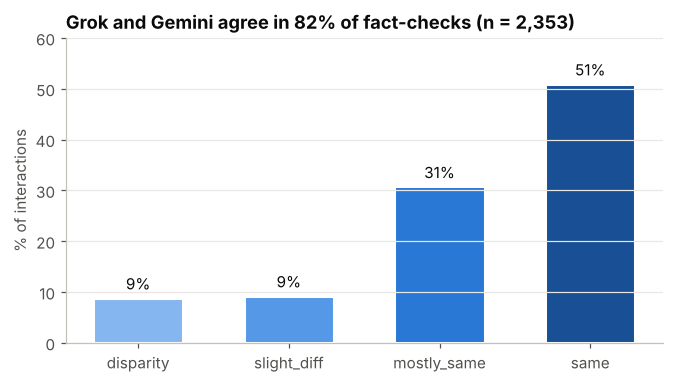

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(VERDICT_ORDER, share.values, color=VERDICT_COLORS, width=0.6, edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in share.values], padding=3, color=INK)
ax.set_ylabel("% of interactions")
ax.set_ylim(0, 60)
ax.grid(axis="x", visible=False)
ax.set_title(f"Grok and Gemini agree in {share['same'] + share['mostly_same']:.0f}% of fact-checks (n = {obs.sum():,})")
save(fig, "01_verdict_distribution")

## 3. What explains disagreement?

Agreement is ordinal, so each factor is tested with **Kruskal-Wallis**, reporting effect size (epsilon squared: 0.01 small, 0.08 medium, 0.26 large) to separate statistical significance from practical relevance in a large sample. Topic gets a **Dunn post-hoc** test with Holm correction.

In [6]:
def summary_by(col, value="verdict_num"):
    g = df.groupby(col)[value]
    return g.agg(n="count", median="median", mean="mean").round(3).sort_values("mean", ascending=False)

def run_kruskal(col, value="verdict_num", min_n=5):
    sub = df[[col, value]].dropna()
    groups = {k: g[value].values for k, g in sub.groupby(col) if len(g) >= min_n}
    h, p = kruskal(*groups.values())
    eps2 = h / (len(sub) - 1)
    print(f"Kruskal-Wallis | {value} ~ {col}: H = {h:.3f}, p = {p:.4g}, eps2 = {eps2:.4f}, n = {len(sub)}")
    return {"H": h, "p": p, "eps2": eps2, "n": len(sub)}

def verdict_shares(col):
    return (pd.crosstab(df[col], df["comparison_verdict"], normalize="index")
              .reindex(columns=VERDICT_ORDER) * 100)

### 3.1 Collection period (2025 vs. 2026)

In [7]:
kw_period = run_kruskal("period")
verdict_shares("period").round(1)

Kruskal-Wallis | verdict_num ~ period: H = 14.564, p = 0.0001355, eps2 = 0.0062, n = 2353


comparison_verdict,disparity,slight_diff,mostly_same,same
period,,,,
2025,10.0,9.5,34.2,46.3
2026,8.0,9.1,28.0,54.9


### 3.2 Language (English vs. Spanish)

In [8]:
kw_lang = run_kruskal("lang")
en = df.loc[df["lang"] == "en", "verdict_num"]
es = df.loc[df["lang"] == "es", "verdict_num"]
u, p_u = mannwhitneyu(en, es, alternative="two-sided")
print(f"Mann-Whitney U (en vs es): U = {u:.1f}, p = {p_u:.4g}")
verdict_shares("lang").round(1)

Kruskal-Wallis | verdict_num ~ lang: H = 10.299, p = 0.001331, eps2 = 0.0044, n = 2353
Mann-Whitney U (en vs es): U = 305813.0, p = 0.001331


comparison_verdict,disparity,slight_diff,mostly_same,same
lang,,,,
en,8.9,10.0,31.4,49.7
es,8.6,5.3,26.7,59.3


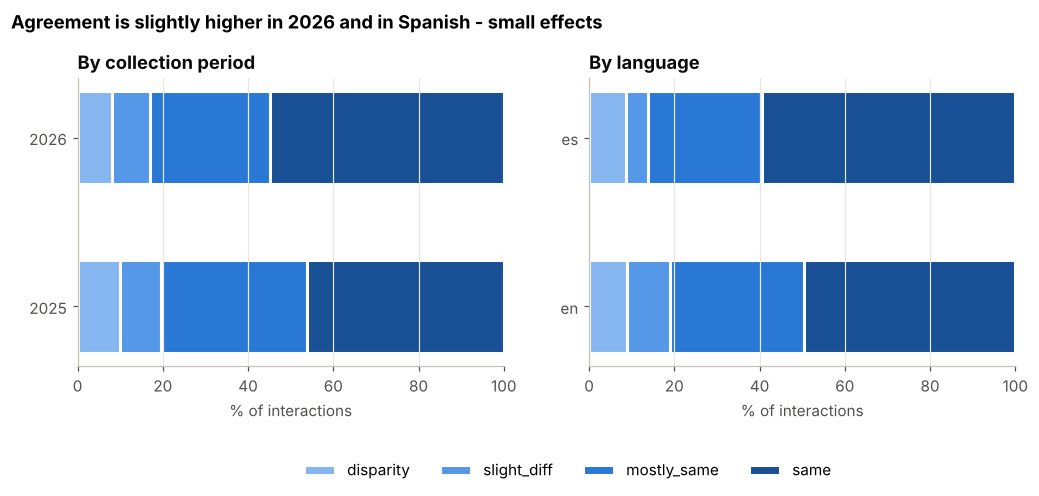

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, col, title in [(axes[0], "period", "By collection period"), (axes[1], "lang", "By language")]:
    tab = verdict_shares(col)
    left = np.zeros(len(tab))
    for v, c in zip(VERDICT_ORDER, VERDICT_COLORS):
        ax.barh(tab.index, tab[v], left=left, color=c, edgecolor="white", linewidth=2, height=0.55, label=v)
        left += tab[v].values
    ax.set_title(title)
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of interactions")
    ax.grid(axis="y", visible=False)
axes[1].legend(ncols=4, loc="upper center", bbox_to_anchor=(-0.05, -0.28), frameon=False)
fig.suptitle("Agreement is slightly higher in 2026 and in Spanish - small effects", x=0.07, y=1.06, ha="left", fontweight="bold")
save(fig, "02_verdict_by_period_language")

### 3.3 Topic

In [10]:
kw_theme = run_kruskal("theme")
summary_by("theme")

Kruskal-Wallis | verdict_num ~ theme: H = 33.136, p = 0.001626, eps2 = 0.0141, n = 2353


,n,median,mean
theme,,,
history_education,109,4.0,3.486
health_medicine,93,4.0,3.441
conspiracy_misinformation,136,4.0,3.412
other,44,3.5,3.364
celebrities_entertainment,140,4.0,3.329
crime_justice,150,4.0,3.267
science_technology,159,4.0,3.252
government_policy,169,3.0,3.237
social_media_viral,98,4.0,3.235


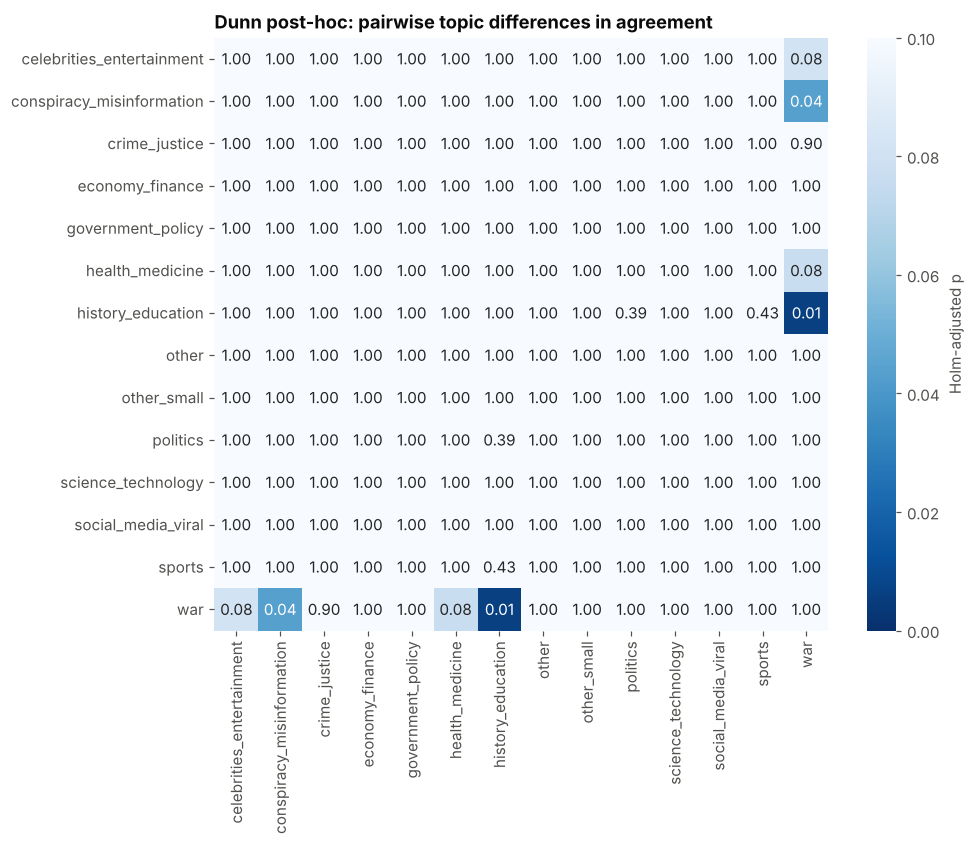

In [11]:
dunn = sp.posthoc_dunn(df[["theme", "verdict_num"]], val_col="verdict_num", group_col="theme", p_adjust="holm")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(dunn, annot=True, fmt=".2f", cmap="Blues_r", vmin=0, vmax=0.1, cbar_kws={"label": "Holm-adjusted p"}, ax=ax)
ax.set_title("Dunn post-hoc: pairwise topic differences in agreement")
ax.grid(False)
save(fig, "03_dunn_topic")

### 3.4 Judge confidence by topic, and multiple-testing correction

In [12]:
kw_conf = run_kruskal("theme", value="verdict_confidence")
family = {"Period": kw_period, "Topic": kw_theme, "Language": kw_lang, "Confidence by topic": kw_conf}
reject, p_holm, _, _ = multipletests([r["p"] for r in family.values()], method="holm")
pd.DataFrame({
    "H": [r["H"] for r in family.values()],
    "p": [r["p"] for r in family.values()],
    "eps2": [r["eps2"] for r in family.values()],
    "p_holm": p_holm,
    "significant": reject,
}, index=family.keys()).round(5)

Kruskal-Wallis | verdict_confidence ~ theme: H = 46.054, p = 1.394e-05, eps2 = 0.0196, n = 2353


,H,p,eps2,p_holm,significant
Period,14.56407,0.00014,0.00619,0.00041,True
Topic,33.13579,0.00163,0.01409,0.00266,True
Language,10.29934,0.00133,0.00438,0.00266,True
Confidence by topic,46.05405,0.00001,0.01958,0.00006,True


### 3.5 Is the judge model's confidence meaningful?

If the judge is well calibrated, it should be more confident when the two fact-checks clearly agree. A strong positive Spearman correlation supports the validity of the annotation pipeline.

Spearman rho = 0.658, p = 1.97e-292, n = 2353


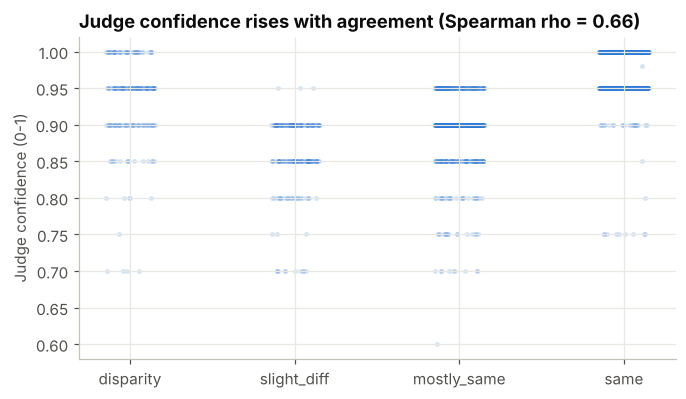

In [13]:
rho, p_sp = spearmanr(df["verdict_confidence"], df["verdict_num"])
print(f"Spearman rho = {rho:.3f}, p = {p_sp:.3g}, n = {len(df)}")

fig, ax = plt.subplots(figsize=(7, 3.8))
jitter = RNG.uniform(-0.15, 0.15, len(df))
ax.scatter(df["verdict_num"] + jitter, df["verdict_confidence"], s=10, alpha=0.2, color=BLUE, linewidths=0)
ax.set_xticks([1, 2, 3, 4], VERDICT_ORDER)
ax.set_ylabel("Judge confidence (0-1)")
ax.set_title(f"Judge confidence rises with agreement (Spearman rho = {rho:.2f})")
save(fig, "04_confidence_vs_agreement")

## 4. Robustness check: ordinal logistic regression

Agreement regressed on topic, language and period **at the same time**, to check whether each effect survives once the others are controlled for (instead of three separate univariate stories).

In [14]:
reg = df[["verdict_num", "theme", "lang", "period"]].dropna()
X = pd.get_dummies(reg[["theme", "lang", "period"]], drop_first=True).astype(float)
model = OrderedModel(reg["verdict_num"].astype(int), X, distr="logit")
res = model.fit(method="bfgs", disp=False)
print(res.summary())

                             OrderedModel Results                             
Dep. Variable:            verdict_num   Log-Likelihood:                -2659.8
Model:                   OrderedModel   AIC:                             5356.
Method:            Maximum Likelihood   BIC:                             5459.
Date:                Mon, 19 Oct 2026                                         
Time:                        19:44:26                                         
No. Observations:                2353                                         
Df Residuals:                    2335                                         
Df Model:                          15                                         
                                      coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------
theme_conspiracy_misinformation    -0.0234      0.238     -0.099      0.922      -0.490  

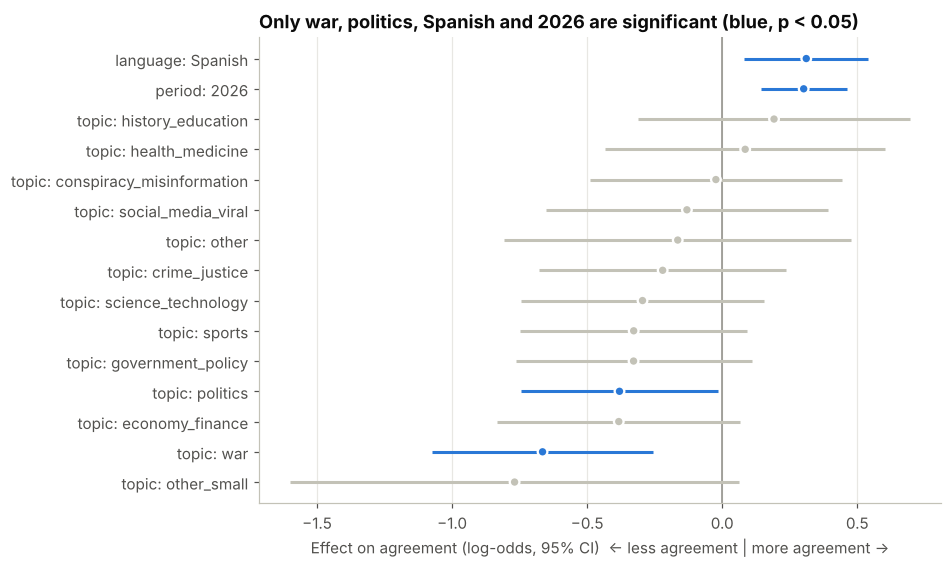

,coef,low,high,p
topic: other_small,-0.769,-1.600,0.063,0.070
topic: war,-0.665,-1.073,-0.258,0.001
topic: economy_finance,-0.383,-0.833,0.067,0.096
topic: politics,-0.380,-0.744,-0.016,0.041
topic: government_policy,-0.328,-0.765,0.108,0.141
topic: sports,-0.328,-0.748,0.092,0.126
topic: science_technology,-0.295,-0.744,0.154,0.198
topic: crime_justice,-0.220,-0.678,0.237,0.345
topic: other,-0.165,-0.806,0.477,0.615
topic: social_media_viral,-0.131,-0.652,0.391,0.623


In [15]:
coef = pd.DataFrame({"coef": res.params, "low": res.conf_int()[0], "high": res.conf_int()[1], "p": res.pvalues}).loc[X.columns]
coef.index = (coef.index.str.replace("theme_", "topic: ").str.replace("lang_es", "language: Spanish")
                         .str.replace("period_2026", "period: 2026"))
coef = coef.sort_values("coef")
sig = coef["p"] < 0.05

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.axvline(0, color="#8c8b85", linewidth=1)
ax.hlines(coef.index, coef["low"], coef["high"], color=np.where(sig, BLUE, "#c3c2b7"), linewidth=2)
ax.scatter(coef["coef"], coef.index, s=40, color=np.where(sig, BLUE, "#c3c2b7"), zorder=3, edgecolor="white", linewidth=1.5)
ax.set_xlabel("Effect on agreement (log-odds, 95% CI)  <- less agreement | more agreement ->")
ax.set_title("Only war, politics, Spanish and 2026 are significant (blue, p < 0.05)")
ax.grid(axis="y", visible=False)
save(fig, "05_ordinal_regression")
coef.round(3)

## 5. Methodological checks

**Topic composition.** If topics are distributed differently across languages or periods, the language/period effects could be a proxy for topic. A chi-square test of homogeneity (with Cramér's V) checks this.

In [16]:
def chi2_homogeneity(col):
    ct = pd.crosstab(df["theme"], df[col])
    chi2, p, dof, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"topic x {col}: chi2 = {chi2:.2f}, p = {p:.3g}, dof = {dof}, Cramer's V = {v:.3f}")

chi2_homogeneity("lang")
chi2_homogeneity("period")

topic x lang: chi2 = 39.12, p = 0.000191, dof = 13, Cramer's V = 0.129
topic x period: chi2 = 137.77, p = 5.87e-23, dof = 13, Cramer's V = 0.242


**Language x period.** A Cochran-Mantel-Haenszel test checks whether the language effect holds *within* each period, and a two-way ANOVA tests for an interaction.

In [17]:
df["agree"] = np.where(df["comparison_verdict"].isin(["same", "mostly_same"]), "agree", "disagree")
tables = [pd.crosstab(g["agree"], g["lang"]).reindex(index=["agree", "disagree"], columns=["en", "es"], fill_value=0).values
          for _, g in df.groupby("period")]
st = StratifiedTable(tables)
low, high = st.oddsratio_pooled_confint()
print(st.test_null_odds())
print(f"Pooled Mantel-Haenszel OR = {st.oddsratio_pooled:.3f} (95% CI {low:.2f}-{high:.2f})")

ols = smf.ols("verdict_num ~ C(lang) * C(period)", data=df).fit()
anova_lm(ols, typ=2).round(4)

pvalue      0.030510699952342124
statistic   4.680284224554987
Pooled Mantel-Haenszel OR = 0.697 (95% CI 0.50-0.97)


,sum_sq,df,F,PR(>F)
C(lang),6.2635,1.0,6.9908,0.0082
C(period),9.6430,1.0,10.7629,0.0011
C(lang):C(period),0.1039,1.0,0.1160,0.7335
Residual,2104.5952,2349.0,NaN,NaN


## 6. Corrective reach: does the correction reach anyone?

First, which engagement metrics are usable? Nearly all of them are zero for Grok's replies, so the analysis uses **views only**, on a `log1p` scale.

In [18]:
ENG = ["viewCount", "likeCount", "retweetCount", "replyCount", "quoteCount", "bookmarkCount"]
(df[ENG].eq(0).mean() * 100).round(1).rename("% zeros").to_frame()

,% zeros
viewCount,0.0
likeCount,99.3
retweetCount,99.5
replyCount,99.3
quoteCount,99.9
bookmarkCount,100.0


In [19]:
df["log_views"] = np.log1p(df["viewCount"])
print(f"Grok reply views: median = {df['viewCount'].median():.0f}, "
      f"IQR = {df['viewCount'].quantile(.25):.0f}-{df['viewCount'].quantile(.75):.0f}, max = {df['viewCount'].max():,}")
df.groupby(["period", "lang"])["log_views"].agg(median="median", mean="mean", n="count").round(3)

Grok reply views: median = 52, IQR = 26-124, max = 111,351


median   mean     n
period lang                     
2025   en     4.060  4.263   905
       es     4.205  4.683   145
2026   en     3.761  4.070  1111
       es     4.350  4.835   192

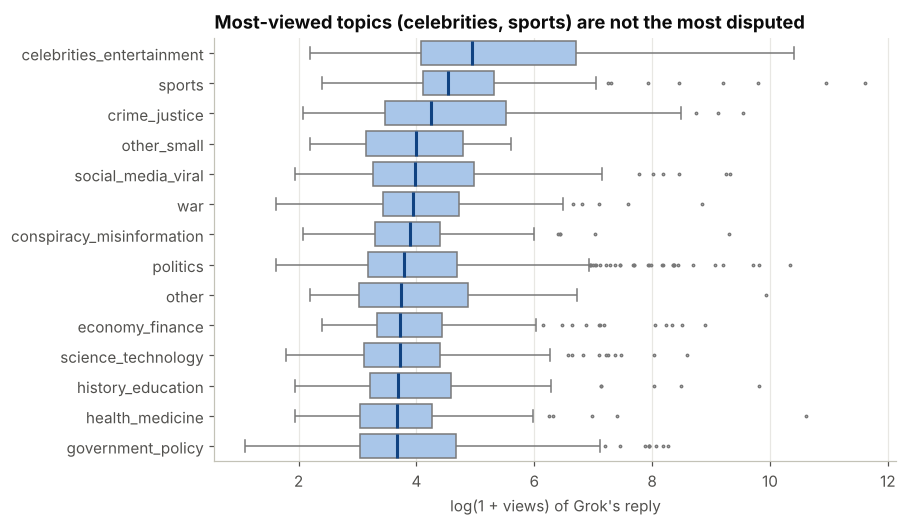

In [20]:
order = df.groupby("theme")["log_views"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, y="theme", x="log_views", order=order, color="#9ec5f4", fliersize=1.5,
            linewidth=1, medianprops={"color": "#104281", "linewidth": 2}, ax=ax)
ax.set_xlabel("log(1 + views) of Grok's reply")
ax.set_ylabel("")
ax.set_title("Most-viewed topics (celebrities, sports) are not the most disputed")
save(fig, "06_views_by_topic")

### Capture ratio

`capture ratio = views of Grok's reply / views of the claim it fact-checks`. A ratio of 0.1 means the correction reached 10% of the original audience. Both counts were captured at scraping time (see limitations).

In [21]:
r = df[df["claim_viewCount"] > 0].copy()
r["capture_ratio"] = r["viewCount"] / r["claim_viewCount"]
med = r["capture_ratio"].median()
print(f"Interactions with claim views > 0: {len(r)}")
print(f"Median capture ratio: {med:.4f}  ->  the typical correction reaches {med:.1%} of the claim's audience")
print(f"Grok's reply out-views the claim (ratio > 1): {(r['capture_ratio'] > 1).mean():.1%}")
r["capture_ratio"].describe().round(4)

Interactions with claim views > 0: 2351
Median capture ratio: 0.0031  ->  the typical correction reaches 0.3% of the claim's audience
Grok's reply out-views the claim (ratio > 1): 9.9%


count    2351.0000
mean        0.3234
std         1.2926
min         0.0000
25%         0.0002
50%         0.0031
75%         0.4080
max        55.5818
Name: capture_ratio, dtype: float64

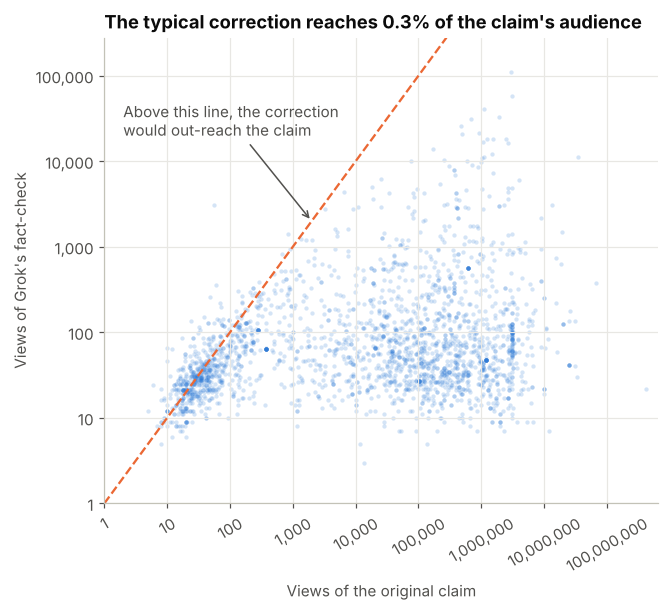

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
x, y = np.log10(r["claim_viewCount"] + 1), np.log10(r["viewCount"] + 1)
ax.scatter(x, y, s=8, alpha=0.2, color=BLUE, linewidths=0)
xmax, ymax = x.max() + 0.2, y.max() + 0.4
ax.plot([0, ymax], [0, ymax], color=ORANGE, linewidth=1.5, linestyle="--")
ax.annotate("Above this line, the correction\nwould out-reach the claim", xy=(3.3, 3.3), xytext=(0.3, 4.3), color=INK_2, arrowprops={"arrowstyle": "->", "color": INK_2})
ax.set_xlim(0, xmax)
ax.set_ylim(0, ymax)
ax.set_xticks(range(0, int(xmax) + 1), [f"{10**t:,}" for t in range(0, int(xmax) + 1)], rotation=30)
ax.set_yticks(range(0, int(ymax) + 1), [f"{10**t:,}" for t in range(0, int(ymax) + 1)])
ax.set_xlabel("Views of the original claim")
ax.set_ylabel("Views of Grok's fact-check")
ax.set_title(f"The typical correction reaches {med:.1%} of the claim's audience")
save(fig, "07_capture_ratio")

## 7. Conclusions

- **Agreement is high:** Grok and an independent model reach the same or mostly the same verdict in ~82% of interactions, far from what two unrelated judges would produce.
- **Disagreement is topical, not diffuse:** with all variables controlled, only war (-0.67) and politics (-0.38) reduce agreement; Spanish (+0.31) and 2026 (+0.30) increase it slightly. Effect sizes are small throughout.
- **The bottleneck is reach, not judgement:** the median correction reaches 0.3% of the audience of the claim it checks, and only about 1 in 10 out-views the original.

**Limitations.** The study measures *consistency* between models, not accuracy against human ground truth; the sample is skewed towards English (2,016 vs. 337); view counts are a snapshot at scraping time, so the audience before and after Grok's reply cannot be separated.